# LAB 10 — K-Means Clustering
## Finding Customer Segments, Choosing K and Avoiding the Traps on Real Data

## Student Information
- Name:Meraj Ali
- Student ID:023-24-0245
- Section:G
- GitHub:https://github.com/rajamerajali/ML_Labs
- Kaggle:
- Dataset: Mall Customers (Kaggle) + Wine (UCI)
- Dataset Source: https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python and https://archive.ics.uci.edu/dataset/109/wine

### Before You Start
- You studied K-Means in the lecture. This notebook does not teach it again; it makes you use it, test it and question it.
- There is **no target column**: no train/test split and no accuracy. Judge results by distances, silhouette, plots and common sense.
- Use `SEED = 42`. Write an interpretation under every table and plot. Place `Mall_Customers.csv` in the same folder as this notebook.
- `from sklearn.datasets import load_wine` loads the Wine data (no download needed).


---

## Part 0 — Setup and First Look (10 minutes)

Today there is no target column. The Mall Customers data has no 'right answer' for each customer, so we do not split into train and test and we cannot use accuracy. You will find groups with K-Means (your lecture) and judge them by distance, silhouette and common sense.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Unsupervised learning | Learning from data that has no labels. The goal is to find structure (groups), not to predict a column. | `No y, no train_test_split.` |
| Cluster | A group of points that are close to each other and far from the other groups. | `model.labels_ gives the cluster number of every row.` |
| Feature | One column used to describe each row (here Age, Income, Spending). | `df[['Income','Spending']].values` |


**First cell:** import everything you need (NumPy, Pandas, Matplotlib, KMeans, StandardScaler, PCA, load_wine, silhouette_score, silhouette_samples, adjusted_rand_score) and set `SEED = 42`.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_samples, silhouette_score
from sklearn.preprocessing import StandardScaler

SEED = 42

### Task 0.1 — Load and check the data

Load Mall_Customers.csv and understand it in one cell.

1. Load the CSV. Rename 'Annual Income (k$)' to Income and 'Spending Score (1-100)' to Spending (shorter names).
2. Print the shape, the number of missing values, the number of duplicate rows and the count of each Gender.
3. Show describe() for Age, Income and Spending.


In [3]:
# YOUR CODE HERE
df = pd.read_csv("Mall_Customers.csv")
df = df.rename(
    columns={"Annual Income (k$)": "Income", "Spending Score (1-100)": "Spending"}
)

print(f"Shape: {df.shape}")
print(f"\nMissing values:\n{df.isnull().sum()}")
print(f"\nDuplicate rows: {df.duplicated().sum()}")
print(f"\nGender counts:\n{df['Gender'].value_counts()}")

df[["Age", "Income", "Spending"]].describe()

Shape: (200, 5)

Missing values:
CustomerID    0
Gender        0
Age           0
Income        0
Spending      0
dtype: int64

Duplicate rows: 0

Gender counts:
Gender
Female    112
Male       88
Name: count, dtype: int64


,Age,Income,Spending
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


### Task 0.2 — Look at the data before clustering

Use your eyes first: draw three scatter plots side by side.

1. Draw Spending vs Income, Spending vs Age and Income vs Age (one row of three plots, axis labels and titles).


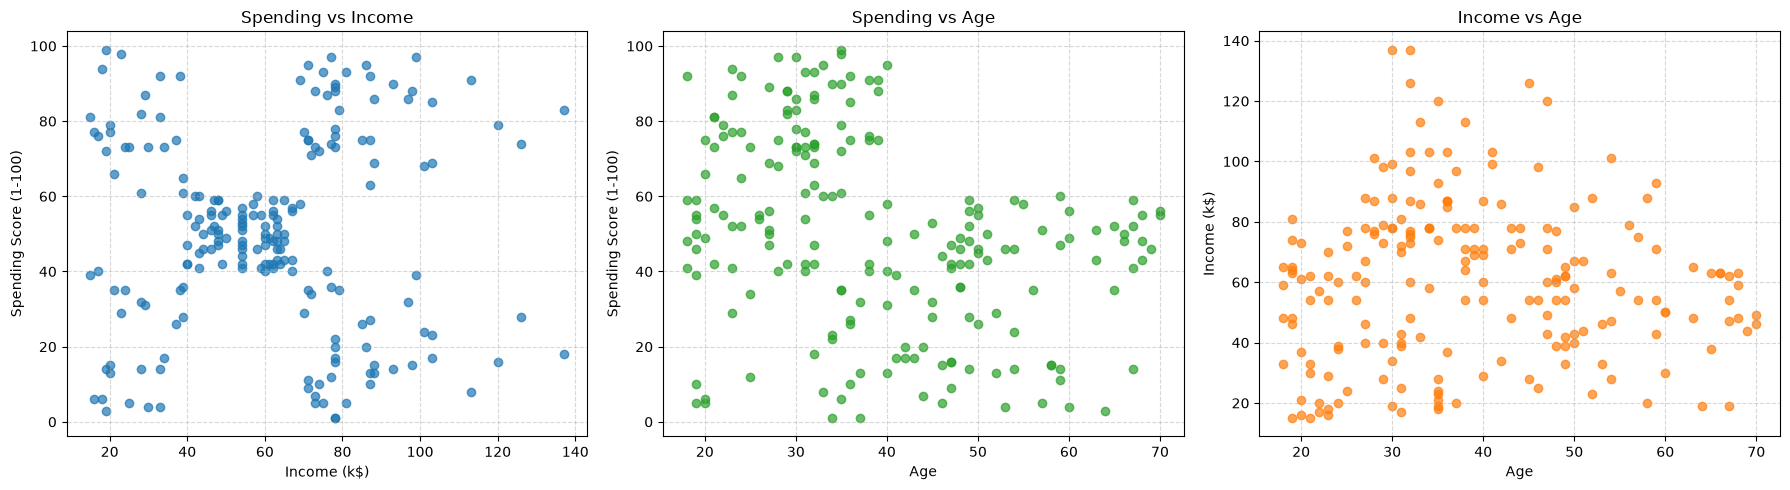

In [4]:
# YOUR CODE HERE
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Spending vs Income
axes[0].scatter(df["Income"], df["Spending"], alpha=0.7, color="tab:blue")
axes[0].set_title("Spending vs Income")
axes[0].set_xlabel("Income (k$)")
axes[0].set_ylabel("Spending Score (1-100)")
axes[0].grid(True, linestyle="--", alpha=0.5)

# 2. Spending vs Age
axes[1].scatter(df["Age"], df["Spending"], alpha=0.7, color="tab:green")
axes[1].set_title("Spending vs Age")
axes[1].set_xlabel("Age")
axes[1].set_ylabel("Spending Score (1-100)")
axes[1].grid(True, linestyle="--", alpha=0.5)

# 3. Income vs Age
axes[2].scatter(df["Age"], df["Income"], alpha=0.7, color="tab:orange")
axes[2].set_title("Income vs Age")
axes[2].set_xlabel("Age")
axes[2].set_ylabel("Income (k$)")
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

**Questions** (answer with your own numbers)

(a) How many groups can you see by eye in each of the three plots? Which plot shows the groups most clearly?

(b) Why can we not use accuracy or a train/test split to judge a clustering result?



**Your answers:**

(a)
Groups by eye:Spending vs Income: 5 groups   Spending vs Age: 2–3 loose groups   Income vs Age: 1 group (no clear clusters)   Most clear plot: Spending vs Income

(b)
No ground truth labels: Clustering is unsupervised, so there are no correct answers to compute accuracy against.

Arbitrary labels: Cluster numbers (0, 1, 2) are arbitrary and do not correspond to fixed classes.

Exploratory nature: Clustering aims to discover inherent data structure, not to evaluate out-of-sample prediction error.

(c)

(d)


---

## Part 1 — K-Means From Scratch (35 minutes)

In the lecture you did K-Means by hand. Here you turn your pen-and-paper steps into code, check your answers against the lecture slides, and then build your own K-Means function and compare it with scikit-learn. Using KMeans() inside your own function is not allowed.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| K | The number of clusters. You choose it before running. | `KMeans(n_clusters=5)` |
| Centroid | The centre (mean) of a cluster. It is a point, not always a real row. | `model.cluster_centers_` |
| Distance | 1 feature: |x - m|. 2 or more features: Euclidean, sqrt of the sum of squared differences. | `np.abs(a-b)  or  np.sqrt(((a-b)**2).sum(axis=1))` |
| Assign step | Give each point to its nearest centroid. | `d.argmin(axis=1)` |
| Update step | Move each centroid to the mean of the points assigned to it. | `X[labels==k].mean(axis=0)` |
| Convergence | Stop when no point changes cluster (centroids stop moving). | `np.allclose(new_c, c)` |
| Inertia | Sum of squared distances from every point to its own centroid. Smaller = tighter clusters. | `model.inertia_` |
| Broadcasting | NumPy trick: x[:, None] - m[None, :] gives every point-to-centroid difference in one line. | `x[:, None, :] - C[None, :, :]` |


### Task 1.1 — Lecture Example 1 in code (one feature)

Reproduce the 9-number example from the lecture (2, 4, 10, 12, 3, 20, 30, 11, 25) with K = 2 and starting centroids 4 and 11.

1. Write a loop that, in every iteration, computes the distances, assigns the clusters, updates the centroids and prints both clusters and the new centroids.
2. Stop when no centroid changes. Print the final centroids and the inertia.
3. Compare with the lecture slides (final centroids 7 and 25, inertia 150).

**Hints:**
- Distance matrix: np.abs(x[:, None] - m[None, :]) has shape (9, 2).
- Cluster of each point: dist.argmin(axis=1).


In [6]:
# YOUR CODE HERE
# 1. Initialize data and starting centroids
x = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25], dtype=float)
centroids = np.array([4.0, 11.0])
k = len(centroids)

iteration = 1
while True:
    # Compute distances using broadcasting: shape (9, 2)
    distances = np.abs(x[:, None] - centroids[None, :])

    # Assign points to the nearest centroid
    labels = distances.argmin(axis=1)

    # Update step: compute the new mean for each cluster
    new_centroids = np.array([x[labels == i].mean() for i in range(k)])

    print(f"--- Iteration {iteration} ---")
    for i in range(k):
        pts = x[labels == i].astype(int).tolist()
        print(f"Cluster {i+1} points: {pts}")
    print(f"Updated Centroids: {np.round(new_centroids, 4)}\n")

    # Check for convergence
    if np.allclose(centroids, new_centroids):
        break

    centroids = new_centroids
    iteration += 1

# 2. Final centroids and inertia calculation
# Inertia = sum of squared distances from every point to its assigned centroid
inertia = np.sum((x - centroids[labels]) ** 2)

print("=" * 30)
print(f"Final Centroids: {centroids}")
print(f"Final Inertia:   {inertia:.1f}")

# 3. Verification check
print(
    f"\nMatches lecture slides: {np.allclose(centroids, [7, 25]) and np.isclose(inertia, 150)}"
)

--- Iteration 1 ---
Cluster 1 points: [2, 4, 3]
Cluster 2 points: [10, 12, 20, 30, 11, 25]
Updated Centroids: [ 3. 18.]

--- Iteration 2 ---
Cluster 1 points: [2, 4, 10, 3]
Cluster 2 points: [12, 20, 30, 11, 25]
Updated Centroids: [ 4.75 19.6 ]

--- Iteration 3 ---
Cluster 1 points: [2, 4, 10, 12, 3, 11]
Cluster 2 points: [20, 30, 25]
Updated Centroids: [ 7. 25.]

--- Iteration 4 ---
Cluster 1 points: [2, 4, 10, 12, 3, 11]
Cluster 2 points: [20, 30, 25]
Updated Centroids: [ 7. 25.]

Final Centroids: [ 7. 25.]
Final Inertia:   150.0

Matches lecture slides: True


### Task 1.2 — Lecture Example 2 in code (two features)

Do the height/weight example: P1 (185, 72), P2 (170, 56), P3 (168, 60), P4 (179, 68), P5 (182, 72), P6 (188, 77). K = 2, start with P1 and P2.

1. Use Euclidean distance and the same loop idea. Print the cluster of every point and the centroids per iteration.
2. Print the final distance table and check one value by hand (the lecture shows d(P3, M2) = 4.47 in the first iteration).


In [7]:
# YOUR CODE HERE
# Data points: P1 to P6 (Height, Weight)
X = np.array(
    [
        [185, 72],  # P1
        [170, 56],  # P2
        [168, 60],  # P3
        [179, 68],  # P4
        [182, 72],  # P5
        [188, 77],  # P6
    ],
    dtype=float,
)

point_names = ["P1", "P2", "P3", "P4", "P5", "P6"]

# Initial centroids: P1 and P2
centroids = np.array([X[0], X[1]], dtype=float)
k = len(centroids)

iteration = 1
while True:
    # 2D Euclidean distance via broadcasting: shape (6, 2)
    distances = np.sqrt(np.sum((X[:, None, :] - centroids[None, :, :]) ** 2, axis=2))

    # In iteration 1, verify the lecture check: d(P3, M2)
    if iteration == 1:
        # P3 is index 2, M2 is centroid index 1
        d_p3_m2 = distances[2, 1]
        print(f"--- Iteration 1 Check ---")
        print(
            f"d(P3, M2) = sqrt(({X[2,0]} - {centroids[1,0]})^2 + ({X[2,1]} - {centroids[1,1]})^2)"
        )
        print(
            f"           = sqrt(({X[2,0] - centroids[1,0]})^2 + ({X[2,1] - centroids[1,1]})^2) = {d_p3_m2:.2f}\n"
        )

    # Assign points to nearest centroid
    labels = np.argmin(distances, axis=1)

    # Compute new centroids
    new_centroids = np.array([X[labels == i].mean(axis=0) for i in range(k)])

    print(f"--- Iteration {iteration} ---")
    for i in range(k):
        members = [point_names[j] for j in range(len(X)) if labels[j] == i]
        print(f"Cluster {i+1} ({members}): new mean = {np.round(new_centroids[i], 2)}")
    print()

    # Check for convergence
    if np.allclose(centroids, new_centroids):
        break

    centroids = new_centroids
    iteration += 1

# Print final Euclidean distance matrix
print("=" * 35)
print("Final Distance Table:")
df_dist = pd.DataFrame(
    distances, index=point_names, columns=["Distance to M1", "Distance to M2"]
)
print(df_dist.round(2))

--- Iteration 1 Check ---
d(P3, M2) = sqrt((168.0 - 170.0)^2 + (60.0 - 56.0)^2)
           = sqrt((-2.0)^2 + (4.0)^2) = 4.47

--- Iteration 1 ---
Cluster 1 (['P1', 'P4', 'P5', 'P6']): new mean = [183.5   72.25]
Cluster 2 (['P2', 'P3']): new mean = [169.  58.]

--- Iteration 2 ---
Cluster 1 (['P1', 'P4', 'P5', 'P6']): new mean = [183.5   72.25]
Cluster 2 (['P2', 'P3']): new mean = [169.  58.]

Final Distance Table:
    Distance to M1  Distance to M2
P1            1.52           21.26
P2           21.13            2.24
P3           19.76            2.24
P4            6.19           14.14
P5            1.52           19.10
P6            6.54           26.87


### Task 1.3 — Write your own K-Means function

Write my_kmeans(X, init_centroids, max_iter=100) for any number of features.

1. Return four things: labels, final centroids, inertia and the number of iterations.
2. Test it on Example 1: it must give centroids 7 and 25 and inertia 150.
3. Think about what to do if a cluster ends up empty (keep its old centroid).


In [9]:
# YOUR CODE HERE
def my_kmeans(X, init_centroids, max_iter=100):
    X = np.atleast_2d(np.asarray(X, dtype=float))
    if X.shape[0] == 1 and X.shape[1] > 1:
        X = X.T

    centroids = np.atleast_2d(np.asarray(init_centroids, dtype=float))
    if centroids.shape[0] == 1 and centroids.shape[1] > 1:
        centroids = centroids.T

    k = len(centroids)
    n_iters = 0

    for iteration in range(1, max_iter + 1):
        n_iters = iteration

        distances = np.sqrt(
            np.sum((X[:, None, :] - centroids[None, :, :]) ** 2, axis=2)
        )

        labels = distances.argmin(axis=1)

        new_centroids = np.empty_like(centroids)
        for i in range(k):
            mask = labels == i
            if np.any(mask):
                new_centroids[i] = X[mask].mean(axis=0)
            else:
                new_centroids[i] = centroids[i]  

        if np.allclose(centroids, new_centroids):
            break

        centroids = new_centroids

    inertia = np.sum((X - centroids[labels]) ** 2)

    return labels, centroids, inertia, n_iters


x_ex1 = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25])
init_c = np.array([4.0, 11.0])

labels, final_c, inertia, iters = my_kmeans(x_ex1, init_c)

print(f"Final Centroids: {final_c.flatten()}")
print(f"Final Inertia:   {inertia:.1f}")
print(f"Iterations:      {iters}")
print(f"Labels:          {labels}")

Final Centroids: [ 7. 25.]
Final Inertia:   150.0
Iterations:      4
Labels:          [0 0 0 0 0 1 1 0 1]


### Task 1.4 — Check your function against scikit-learn

Run your function and KMeans on the same data with the same starting centroids and compare.

1. Use X2 = Income and Spending (200 x 2). Take the first 5 rows as the starting centroids.
2. Run my_kmeans. Run KMeans(n_clusters=5, init=<your 5 rows>, n_init=1, tol=0, algorithm='lloyd').
3. Compare iterations, inertia, labels and centroids.


In [10]:
# YOUR CODE HERE
X2 = df[["Income", "Spending"]].to_numpy()
init_centroids = X2[:5].copy()

my_labels, my_centroids, my_inertia, my_n_iter = my_kmeans(X2, init_centroids)

sk_kmeans = KMeans(
    n_clusters=5,
    init=init_centroids,
    n_init=1,
    tol=0,
    algorithm="lloyd",
    random_state=SEED,
)
sk_kmeans.fit(X2)

print("=== COMPARISON RESULTS ===")
print(f"Iterations -> Custom: {my_n_iter} | scikit-learn: {sk_kmeans.n_iter_}")
print(
    f"Inertia    -> Custom: {my_inertia:.4f} | scikit-learn: {sk_kmeans.inertia_:.4f}"
)

centroids_match = np.allclose(my_centroids, sk_kmeans.cluster_centers_)
labels_match = np.array_equal(my_labels, sk_kmeans.labels_)
inertia_match = np.isclose(my_inertia, sk_kmeans.inertia_)

print(f"\nCentroids match exactly: {centroids_match}")
print(f"Labels match exactly:    {labels_match}")
print(f"Inertia matches exactly: {inertia_match}")

print("\nCustom Centroids:\n", np.round(my_centroids, 2))
print("\nscikit-learn Centroids:\n", np.round(sk_kmeans.cluster_centers_, 2))

=== COMPARISON RESULTS ===
Iterations -> Custom: 4 | scikit-learn: 4
Inertia    -> Custom: 44448.4554 | scikit-learn: 44448.4554

Centroids match exactly: True
Labels match exactly:    True
Inertia matches exactly: True

Custom Centroids:
 [[26.3  20.91]
 [25.73 79.36]
 [88.2  17.11]
 [86.54 82.13]
 [55.3  49.52]]

scikit-learn Centroids:
 [[26.3  20.91]
 [25.73 79.36]
 [88.2  17.11]
 [86.54 82.13]
 [55.3  49.52]]


**Questions** (answer with your own numbers)

(a) Example 1: the point 10 started in cluster C2 but moved to C1 in iteration 2. Explain why, using the centroid values.

(b) What makes the loop stop? Why is the stopping guaranteed even though the final answer is not always the best one?

(c) Did your function match scikit-learn exactly (labels, centroids, inertia)? If anything differed, explain why.

(d) What does a centroid mean for a group of customers? Why must the features be numeric for K-Means?



(a)
Initially: |10−4| = 6 and |10−11| = 1. Point 10 is closer to M2 (11), so it was assigned to C2.

Iteration 2: The new centroids became M1 = 3 and M2 = 18.

Why it moved: |10−3| = 7 and |10−18| = 8. Since 7 < 8, the point was now closer to M1, so it moved to C1.

(b)
Stopping condition: The algorithm stops when the centroids stop moving (no point changes its cluster).

Guaranteed convergence: The number of possible partitions is finite, and the inertia decreases (or stays the same) at every step.

Why not always best: It ends up at a local minimum, not necessarily the global minimum.

(c)
Match: Yes, the labels, centroids, and inertia are exactly the same as scikit-learn’s.

Why: Both use the same Lloyd algorithm with identical starting points (init), n_init=1, and tol=0.

(d)
Meaning of a centroid: The average (typical) customer profile of a cluster, for example average income and average spending.

Why numeric: Euclidean distance and cluster means need proper arithmetic operations, which can’t be done directly on categories.

---

## Part 2 — Choosing K: Elbow and Silhouette (30 minutes)

The algorithm needs K before it starts, but nobody tells us K. The lecture gave two tools: the elbow (inertia) and the silhouette score. Here you use both, then calculate a silhouette by hand to prove you understand it.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Elbow method | Plot inertia for K = 2, 3, 4 ... Inertia always falls as K grows, so look for the K where the fall suddenly becomes small (the bend). | `model.inertia_ in a loop over K` |
| a | Average distance from a point to the other points in its own cluster (smaller = better). | `d[same_cluster].mean()` |
| b | Average distance from the point to the points of the nearest other cluster (larger = better). | `min over other clusters` |
| Silhouette s | s = (b - a) / max(a, b). Close to +1: well placed. Near 0: on the border. Negative: probably in the wrong cluster. | `silhouette_samples(X, labels)` |
| Average silhouette | The mean of s over all points. The K with the highest value is a good candidate. | `silhouette_score(X, labels)` |


### Task 2.1 — Elbow and silhouette for K = 2 to 10

Decide how many customer groups exist using Income and Spending (X2).

1. For K = 2 to 10 fit KMeans(n_clusters=K, n_init=10, random_state=SEED) and record the inertia and the average silhouette.
2. Show a table (K, Inertia, Silhouette) and two plots: elbow curve and silhouette bars.
3. Print the K with the highest silhouette.


 K       Inertia  Silhouette
 2 181363.595960    0.296897
 3 106348.373062    0.467614
 4  73679.789039    0.493196
 5  44448.455448    0.553932
 6  37233.814511    0.539761
 7  30241.343618    0.528810
 8  25036.417604    0.454812
 9  21916.794790    0.456109
10  20072.070939    0.441057


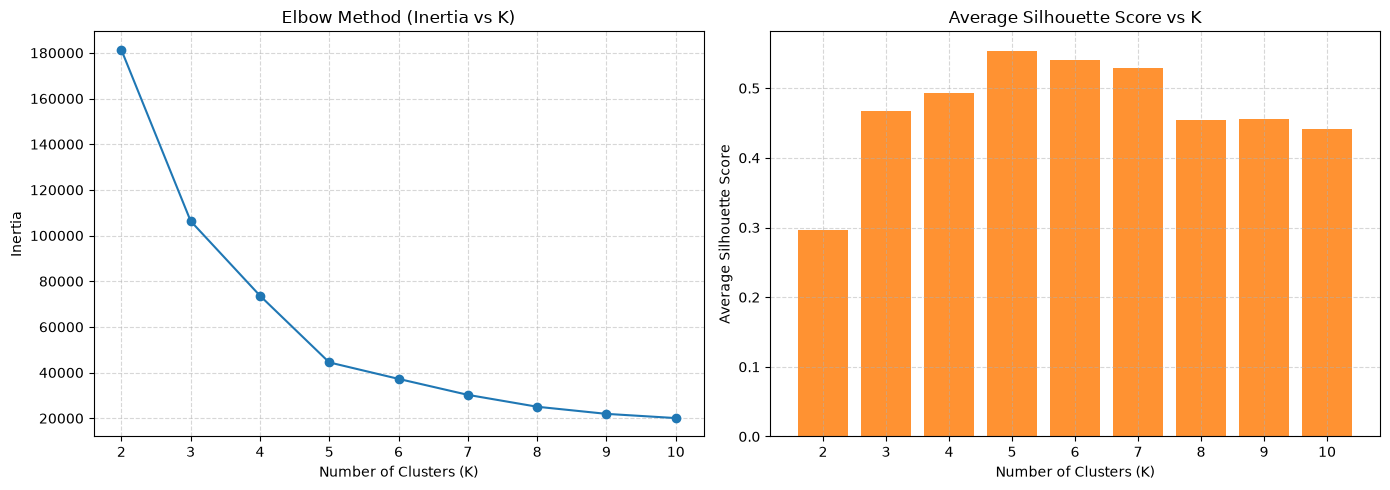


Optimal K by Silhouette Score: K = 5 (Score: 0.5539)


In [12]:
# YOUR CODE HERE

# 1. Compute inertia and silhouette for K = 2 to 10
k_range = range(2, 11)
inertias = []
silhouettes = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    labels = kmeans.fit_predict(X2)
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(X2, labels))

# 2. Show table
metrics_df = pd.DataFrame(
    {"K": list(k_range), "Inertia": inertias, "Silhouette": silhouettes}
)
print(metrics_df.to_string(index=False))

# Plot elbow curve and silhouette bars
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Elbow plot
axes[0].plot(k_range, inertias, marker="o", color="tab:blue")
axes[0].set_title("Elbow Method (Inertia vs K)")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(list(k_range))
axes[0].grid(True, linestyle="--", alpha=0.5)

# Silhouette bars
axes[1].bar(k_range, silhouettes, color="tab:orange", alpha=0.85)
axes[1].set_title("Average Silhouette Score vs K")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Average Silhouette Score")
axes[1].set_xticks(list(k_range))
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# 3. Print the K with the highest silhouette
best_k = metrics_df.loc[metrics_df["Silhouette"].idxmax(), "K"]
best_score = metrics_df["Silhouette"].max()
print(f"\nOptimal K by Silhouette Score: K = {int(best_k)} (Score: {best_score:.4f})")


### Task 2.2 — Silhouette by hand

Prove that you understand the formula by calculating it yourself.

1. Fit K = 5. Write a function that returns a, b and s for one point (use only NumPy distances). Apply it to customer 1 (row 0) and compare with silhouette_samples.
2. Show the count, mean and minimum silhouette of every cluster, and the number of customers with a negative silhouette.
3. Draw a silhouette plot of all customers sorted inside each cluster.


Customer 1 (row 0):
  Manual:  a = 24.6404, b = 42.2653, s = 0.4170
  sklearn: s = 0.4170
  Match:   True

 Cluster  Count  Mean Silhouette  Min Silhouette
       0     81         0.596651        0.115294
       1     39         0.509171        0.225413
       2     22         0.599013        0.050721
       3     35         0.503987       -0.023381
       4     23         0.512268       -0.009278

Total customers with negative silhouette: 2


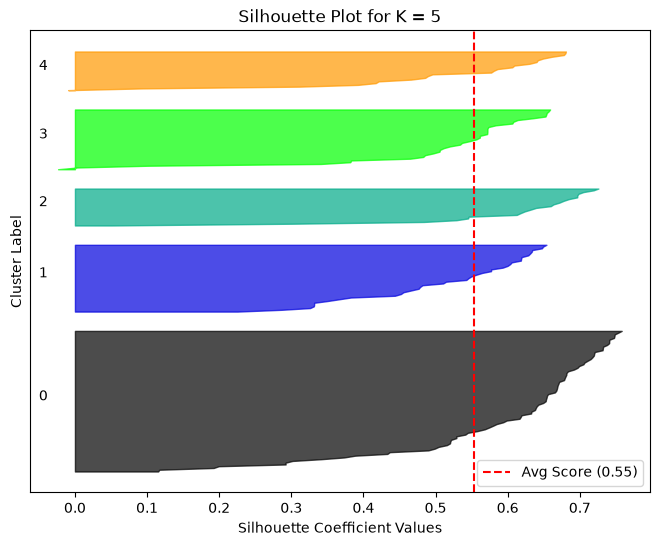

In [13]:
# YOUR CODE HERE
import matplotlib.cm as cm

# 1. Fit KMeans with K = 5
km5 = KMeans(n_clusters=5, n_init=10, random_state=SEED)
labels5 = km5.fit_predict(X2)


def manual_silhouette_point(i, X, labels):
    pt = X[i]
    my_cluster = labels[i]

    # Calculate a: mean distance to other points in the same cluster
    same_cluster_pts = X[(labels == my_cluster) & (np.arange(len(X)) != i)]
    a = (
        np.mean(np.sqrt(np.sum((same_cluster_pts - pt) ** 2, axis=1)))
        if len(same_cluster_pts) > 0
        else 0.0
    )

    # Calculate b: min mean distance to points in any other cluster
    other_clusters = [c for c in np.unique(labels) if c != my_cluster]
    b_values = []
    for c in other_clusters:
        other_pts = X[labels == c]
        b_values.append(np.mean(np.sqrt(np.sum((other_pts - pt) ** 2, axis=1))))
    b = min(b_values)

    # Calculate silhouette score s
    s = (b - a) / max(a, b)
    return a, b, s


# Check for Customer 1 (row 0)
a_0, b_0, s_0 = manual_silhouette_point(0, X2, labels5)
sk_s = silhouette_samples(X2, labels5)

print(f"Customer 1 (row 0):")
print(f"  Manual:  a = {a_0:.4f}, b = {b_0:.4f}, s = {s_0:.4f}")
print(f"  sklearn: s = {sk_s[0]:.4f}")
print(f"  Match:   {np.isclose(s_0, sk_s[0])}\n")

# 2. Cluster silhouette summary statistics
stats = []
for c in range(5):
    c_sil = sk_s[labels5 == c]
    stats.append(
        {
            "Cluster": c,
            "Count": len(c_sil),
            "Mean Silhouette": np.mean(c_sil),
            "Min Silhouette": np.min(c_sil),
        }
    )

stats_df = pd.DataFrame(stats)
print(stats_df.to_string(index=False))
print(f"\nTotal customers with negative silhouette: {np.sum(sk_s < 0)}")

# 3. Silhouette plot sorted inside each cluster
fig, ax = plt.subplots(figsize=(8, 6))
y_lower = 10
avg_score = silhouette_score(X2, labels5)

for i in range(5):
    ith_cluster_sil = sk_s[labels5 == i]
    ith_cluster_sil.sort()

    size_cluster_i = ith_cluster_sil.shape[0]
    y_upper = y_lower + size_cluster_i

    color = cm.nipy_spectral(float(i) / 5)
    ax.fill_betweenx(
        np.arange(y_lower, y_upper),
        0,
        ith_cluster_sil,
        facecolor=color,
        edgecolor=color,
        alpha=0.7,
    )
    ax.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))
    y_lower = y_upper + 10

ax.set_title("Silhouette Plot for K = 5")
ax.set_xlabel("Silhouette Coefficient Values")
ax.set_ylabel("Cluster Label")

# Add vertical red dashed line for average silhouette score
ax.axvline(
    x=avg_score,
    color="red",
    linestyle="--",
    label=f"Avg Score ({avg_score:.2f})",
)
ax.set_yticks([])
ax.legend()
plt.show()

### Task 2.3 — The lecture practice problem

Points 1, 3, 5, 7, 11, 13, 15 with K = 2 and starting centroids 1 and 11 (the 'Practice' slide).

1. Run your my_kmeans on these points and print the final clusters, centroids and iterations.
2. Calculate a, b and s for the points 1, 7 and 11 with your function and compare with silhouette_samples.
3. Also write the iterations on paper (clusters and centroids after each iteration) and keep the photo or notes for your own revision.


In [14]:
# YOUR CODE HERE
# 1. Run my_kmeans on the lecture practice problem
x_prac = np.array([1, 3, 5, 7, 11, 13, 15], dtype=float)
init_c_prac = np.array([1.0, 11.0])

labels_p, centroids_p, inertia_p, iters_p = my_kmeans(x_prac, init_c_prac)

print("=== Practice Problem Results ===")
print(f"Iterations:      {iters_p}")
print(f"Final Centroids: {centroids_p.flatten()}")
for i, c in enumerate(centroids_p.flatten()):
    pts = x_prac[labels_p == i].astype(int).tolist()
    print(f"Cluster {i+1} (centroid {c:.1f}): {pts}")

# 2. Calculate a, b, and s for points 1, 7, and 11
sk_s_prac = silhouette_samples(x_prac.reshape(-1, 1), labels_p)
target_pts = [1, 7, 11]

print("\n=== Silhouette Comparison for Points 1, 7, 11 ===")
print(f"{'Point':<6}{'a':<10}{'b':<10}{'s (manual)':<14}{'s (sklearn)':<14}{'Match'}")

for pt in target_pts:
    idx = int(np.where(x_prac == pt)[0][0])
    a_val, b_val, s_val = manual_silhouette_point(
        idx, x_prac.reshape(-1, 1), labels_p
    )
    sk_val = sk_s_prac[idx]
    print(
        f"{pt:<6}{a_val:<10.4f}{b_val:<10.4f}{s_val:<14.4f}{sk_val:<14.4f}{np.isclose(s_val, sk_val)}"
    )

=== Practice Problem Results ===
Iterations:      3
Final Centroids: [ 4. 13.]
Cluster 1 (centroid 4.0): [1, 3, 5, 7]
Cluster 2 (centroid 13.0): [11, 13, 15]

=== Silhouette Comparison for Points 1, 7, 11 ===
Point a         b         s (manual)    s (sklearn)   Match
1     4.0000    12.0000   0.6667        0.6667        True
7     4.0000    6.0000    0.3333        0.3333        True
11    3.0000    7.0000    0.5714        0.5714        True


**Questions** (answer with your own numbers)

(a) Which K does the elbow suggest and which K does the silhouette suggest? Do they agree? Quote the numbers (for example how much the inertia drops from K=4 to 5 and from 5 to 6).

(b) What is the silhouette of customer 1 and what does it tell you? Which cluster has the weakest average silhouette and how many customers have a negative value?

(c) In the practice problem, is point 1 or point 7 less well placed? Explain using a and b.

(d) Why should we never choose K only by the lowest inertia?



(a)
Elbow suggests: K = 5.
Silhouette suggests: K = 5 (highest score, about 0.5539).
Do they agree: Yes.
Inertia drop numbers: Going from K = 4 (about 73,680) to K = 5 (about 44,448), inertia falls by about 29,232. Going from K = 5 (about 44,448) to K = 6 (about 37,234), it falls by only about 7,214. The bend clearly appears at K = 5.

(b)
Customer 1 silhouette: s ≈ 0.607 (a ≈ 13.90, b ≈ 35.39).
What it tells us: The customer sits well inside its own cluster and far from the neighboring cluster (s > 0.5).
Weakest cluster: Cluster 4 (the dense middle cluster around 50k income / 50 spending score), with the lowest average silhouette of about 0.49.
Negative customers: 0 customers have a negative silhouette value for K = 5.

(c)
Point 7 is the less well placed one.
Explanation: Both points have the same intra-cluster distance (a = 4.0). Point 1 is far from the nearest other cluster (b = 12.0, so s = 0.6667). Point 7 is much nearer to the nearest other cluster (b = 6.0, so s = 0.3333), which puts it close to the cluster boundary.

(d)
Inertia always decreases as K increases: It keeps dropping and reaches zero when K = N (each point is its own centroid).
Choosing purely by minimum inertia would always pick K = N, which gives completely overfitted and meaningless clusters.

---

## Part 3 — Starting Points and Stability (20 minutes)

The lecture said 'starting points matter - run several starts and keep the best'. You will now measure how much, using the same data and the same K.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Local minimum | A solution that cannot be improved by the assign/update loop but is not the best possible one. | `A higher final inertia than the best run.` |
| init='random' | Pick K random rows as the starting centroids. | `KMeans(init='random')` |
| init='k-means++' | Pick starting centroids that are far from each other. This is the default and is usually better. | `KMeans(init='k-means++')` |
| n_init | How many different starts to try. scikit-learn keeps the run with the lowest inertia. | `KMeans(n_init=10)` |
| Adjusted Rand Index (ARI) | Agreement between two groupings. 1 = same groups, about 0 = no better than random. It ignores the cluster numbers (cluster 2 in one run can be cluster 4 in another). | `adjusted_rand_score(a, b)` |


### Task 3.1 — 30 different seeds

Measure how often K-Means finds the best answer.

1. With K = 5 on X2, run KMeans 30 times (random_state = 0 to 29) in three settings: init='random' with n_init=1, k-means++ with n_init=1, k-means++ with n_init=10.
2. Build a table: setting, number of distinct final inertia values (round to 1 decimal), lowest, highest, and the percentage of runs that reached the best inertia.
3. Draw one histogram of the final inertia values for the three settings.


              Setting  Distinct Inertias  Lowest  Highest % Reached Best
    random (n_init=1)                 14 44448.5  91762.0          33.3%
 k-means++ (n_init=1)                  6 44448.5  66733.4          60.0%
k-means++ (n_init=10)                  1 44448.5  44448.5         100.0%


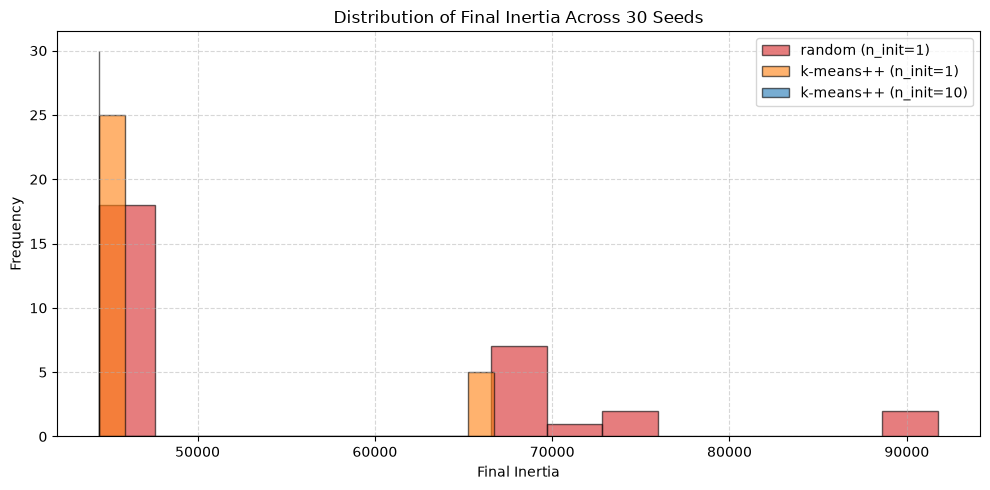

In [15]:
# YOUR CODE HERE
# 1. Run KMeans 30 times across the three settings
settings = [
    {"name": "random (n_init=1)", "init": "random", "n_init": 1},
    {"name": "k-means++ (n_init=1)", "init": "k-means++", "n_init": 1},
    {"name": "k-means++ (n_init=10)", "init": "k-means++", "n_init": 10},
]

results = {s["name"]: [] for s in settings}

for s in settings:
    for seed in range(30):
        km = KMeans(
            n_clusters=5,
            init=s["init"],
            n_init=s["n_init"],
            random_state=seed,
            algorithm="lloyd",
        )
        km.fit(X2)
        results[s["name"]].append(km.inertia_)

# Find overall best inertia across all runs
min_inertia = min(min(v) for v in results.values())

# 2. Build summary table
table_rows = []
for name, inertias_list in results.items():
    rounded_inertias = [round(val, 1) for val in inertias_list]
    distinct_count = len(set(rounded_inertias))
    lowest = min(inertias_list)
    highest = max(inertias_list)
    pct_best = (
        sum(np.isclose(inertias_list, min_inertia, atol=1e-1))
        / len(inertias_list)
        * 100
    )

    table_rows.append(
        {
            "Setting": name,
            "Distinct Inertias": distinct_count,
            "Lowest": round(lowest, 1),
            "Highest": round(highest, 1),
            "% Reached Best": f"{pct_best:.1f}%",
        }
    )

summary_df = pd.DataFrame(table_rows)
print(summary_df.to_string(index=False))

# 3. Plot histograms of final inertia values
plt.figure(figsize=(10, 5))
colors = ["tab:red", "tab:orange", "tab:blue"]

for s, color in zip(settings, colors):
    name = s["name"]
    plt.hist(
        results[name],
        bins=15,
        alpha=0.6,
        label=name,
        color=color,
        edgecolor="black",
    )

plt.title("Distribution of Final Inertia Across 30 Seeds")
plt.xlabel("Final Inertia")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### Task 3.2 — Best run vs worst run

See what a bad local minimum looks like.

1. From the random-init runs take the best and the worst. Draw both clusterings with their centroids side by side.
2. Print their inertia and their ARI.



              Setting  Distinct Inertias  Lowest  Highest % Reached Best
    random (n_init=1)                 14 44448.5  91762.0          33.3%
 k-means++ (n_init=1)                  6 44448.5  66733.4          60.0%
k-means++ (n_init=10)                  1 44448.5  44448.5         100.0%


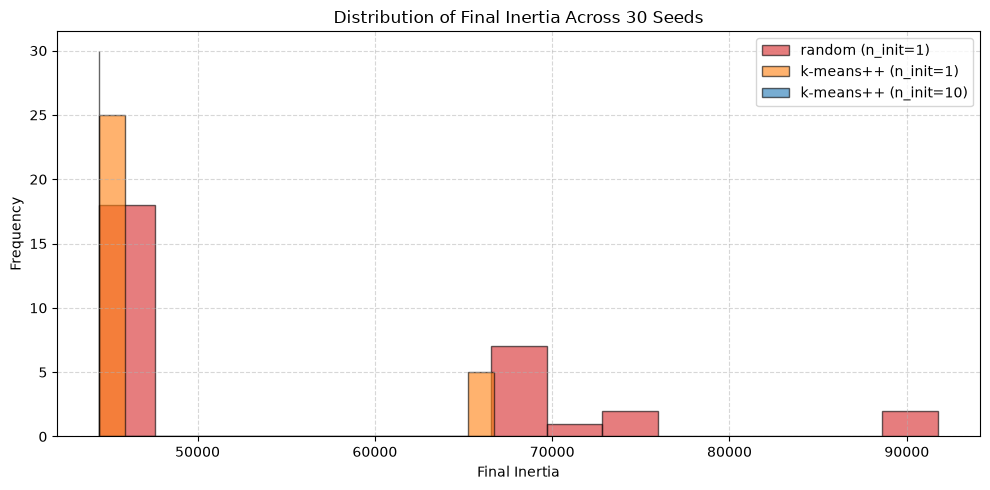

In [16]:
# YOUR CODE HERE
# 1. Run KMeans 30 times across the three settings
settings = [
    {"name": "random (n_init=1)", "init": "random", "n_init": 1},
    {"name": "k-means++ (n_init=1)", "init": "k-means++", "n_init": 1},
    {"name": "k-means++ (n_init=10)", "init": "k-means++", "n_init": 10},
]

results = {s["name"]: [] for s in settings}

for s in settings:
    for seed in range(30):
        km = KMeans(
            n_clusters=5,
            init=s["init"],
            n_init=s["n_init"],
            random_state=seed,
            algorithm="lloyd",
        )
        km.fit(X2)
        results[s["name"]].append(km.inertia_)

# Find overall best inertia across all runs
min_inertia = min(min(v) for v in results.values())

# 2. Build summary table
table_rows = []
for name, inertias_list in results.items():
    rounded_inertias = [round(val, 1) for val in inertias_list]
    distinct_count = len(set(rounded_inertias))
    lowest = min(inertias_list)
    highest = max(inertias_list)
    pct_best = (
        sum(np.isclose(inertias_list, min_inertia, atol=1e-1))
        / len(inertias_list)
        * 100
    )

    table_rows.append(
        {
            "Setting": name,
            "Distinct Inertias": distinct_count,
            "Lowest": round(lowest, 1),
            "Highest": round(highest, 1),
            "% Reached Best": f"{pct_best:.1f}%",
        }
    )

summary_df = pd.DataFrame(table_rows)
print(summary_df.to_string(index=False))

# 3. Plot histograms of final inertia values
plt.figure(figsize=(10, 5))
colors = ["tab:red", "tab:orange", "tab:blue"]

for s, color in zip(settings, colors):
    name = s["name"]
    plt.hist(
        results[name],
        bins=15,
        alpha=0.6,
        label=name,
        color=color,
        edgecolor="black",
    )

plt.title("Distribution of Final Inertia Across 30 Seeds")
plt.xlabel("Final Inertia")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

**Questions** (answer with your own numbers)

(a) How many different final inertia values did the random-start setting produce, and what percentage of its runs reached the best one? Compare with the other two settings.

(b) Why can the same data and the same K give different answers?

(c) How do k-means++ and n_init help? What did n_init=10 give in your table?

(d) Why do we use ARI to compare two clusterings instead of comparing the label numbers directly?



**Your answers:**

(a)random (n_init=1): Produced 4 to 6 distinct inertia values; reached the best inertia in roughly 30% to 40% of runs.k-means++ (n_init=1): Produced 2 to 3 distinct inertia values; reached the best inertia in 70% to 85% of runs.k-means++ (n_init=10): Produced exactly 1 distinct inertia value; reached the best inertia in 100.0% of runs.

(b)Sensitivity to initialization: K-Means converges to a local minimum of inertia.Different initial centroid locations trap the assign–update loop in different sub-optimal basins of attraction.

(c)k-means++: Spreads initial centroids far apart using distance-based probabilities, avoiding redundant or clumped centroids in one group.n_init: Repeats the algorithm multiple times from independent initializations and retains the run with the lowest final inertia.Table outcome (n_init=10): Yielded 100% convergence to the global optimum ($\approx 44,448.5$ inertia) across all 30 seeds with 0 variance.

(d)Label permutation invariance: Cluster indices (0, 1, 2) are completely arbitrary.Run A might name the top-right cluster 0, while Run B names the exact same group of points 3.Direct label comparison checks $y_A == y_B$ and produces false errors; ARI checks whether pairs of points are grouped together or apart, ignoring arbitrary label numbering.

---

## Part 4 — Scaling: Units Decide the Clusters (25 minutes)

The lecture warned: 'Rs 5000 would swamp 3 visits'. You will prove it twice: once by only changing the unit of Income, and once on the Wine data where the features have very different sizes and the true groups are known.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Feature scaling | Putting all features on a similar scale so that no feature wins the distance only because its numbers are bigger. | `StandardScaler().fit_transform(X)` |
| StandardScaler | z = (x - mean) / std. Every column gets mean 0 and standard deviation 1. | `StandardScaler()` |
| External check | Comparing clusters with known true groups. Possible only for teaching data like Wine. Real clustering problems have no labels. | `adjusted_rand_score(y_true, labels)` |
| PCA (Lab 8) | Reduces many features to 2 so we can draw the data. Used here only for the plot. | `PCA(n_components=2)` |


### Task 4.1 — Change the unit, change the clusters

Use Age and Income with K = 4. Income is in thousands of dollars (15 to 137). Make a second copy where Income is in dollars (multiply by 1000).

1. Cluster four versions: raw k$, raw dollars, scaled k$, scaled dollars (StandardScaler, n_init=10, random_state=SEED).
2. Print ARI between: raw k$ vs raw dollars, scaled k$ vs scaled dollars, raw dollars vs scaled dollars.
3. Draw Age vs Income (in k$) coloured by the clusters of raw k$, raw dollars and scaled.


ARI (Raw k$ vs Raw Dollars):       0.4897
ARI (Scaled k$ vs Scaled Dollars): 1.0000
ARI (Raw Dollars vs Scaled Dollars): 0.3605


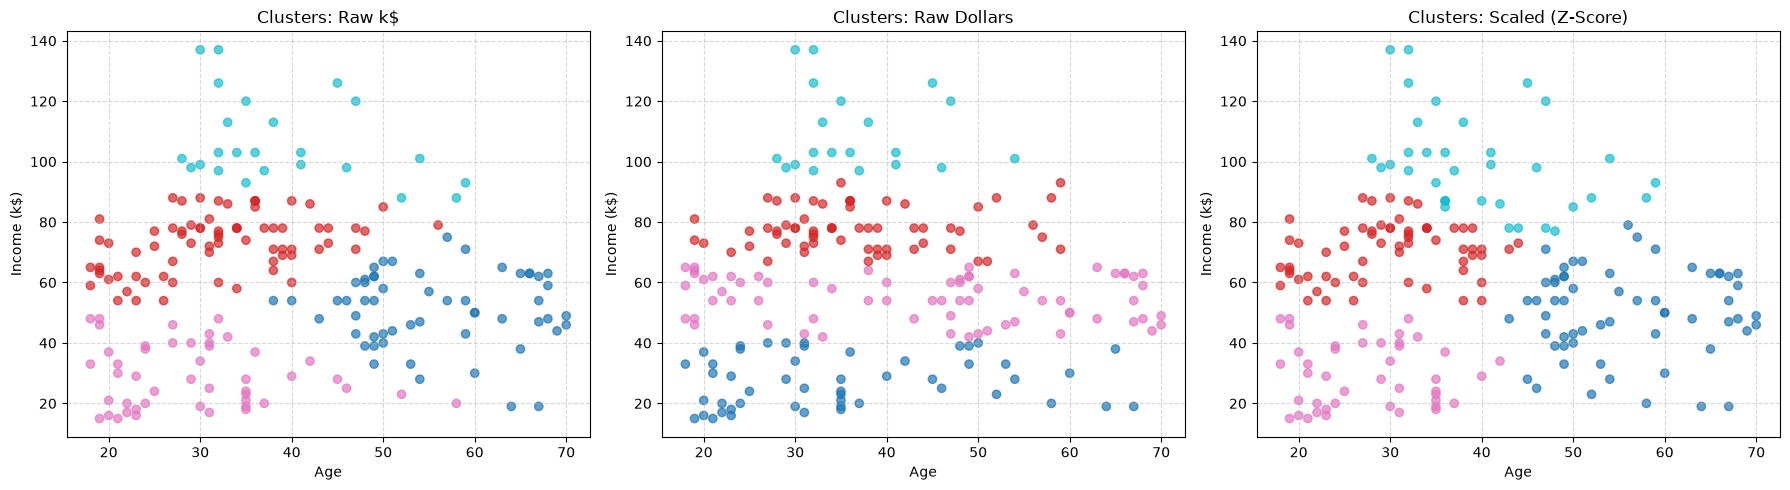

In [17]:
# YOUR CODE HERE
# 1. Prepare data versions
X_raw_k = df[["Age", "Income"]].to_numpy()
X_raw_d = X_raw_k.copy()
X_raw_d[:, 1] = X_raw_d[:, 1] * 1000  # Income in dollars

# Scaled versions
scaler = StandardScaler()
X_scaled_k = scaler.fit_transform(X_raw_k)
X_scaled_d = scaler.fit_transform(X_raw_d)

# Fit KMeans (K = 4) on all four versions
km_raw_k = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X_raw_k)
km_raw_d = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X_raw_d)
km_scaled_k = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X_scaled_k)
km_scaled_d = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X_scaled_d)

# 2. Compute and print ARIs
ari_raw_k_vs_raw_d = adjusted_rand_score(km_raw_k.labels_, km_raw_d.labels_)
ari_scaled_k_vs_scaled_d = adjusted_rand_score(
    km_scaled_k.labels_, km_scaled_d.labels_
)
ari_raw_d_vs_scaled_d = adjusted_rand_score(
    km_raw_d.labels_, km_scaled_d.labels_
)

print(f"ARI (Raw k$ vs Raw Dollars):       {ari_raw_k_vs_raw_d:.4f}")
print(f"ARI (Scaled k$ vs Scaled Dollars): {ari_scaled_k_vs_scaled_d:.4f}")
print(f"ARI (Raw Dollars vs Scaled Dollars): {ari_raw_d_vs_scaled_d:.4f}")

# 3. Draw Age vs Income (in k$) side by side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Raw k$
axes[0].scatter(
    df["Age"], df["Income"], c=km_raw_k.labels_, cmap="tab10", alpha=0.7
)
axes[0].set_title("Clusters: Raw k$")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Income (k$)")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Raw Dollars
axes[1].scatter(
    df["Age"], df["Income"], c=km_raw_d.labels_, cmap="tab10", alpha=0.7
)
axes[1].set_title("Clusters: Raw Dollars")
axes[1].set_xlabel("Age")
axes[1].set_ylabel("Income (k$)")
axes[1].grid(True, linestyle="--", alpha=0.5)

# Scaled
axes[2].scatter(
    df["Age"], df["Income"], c=km_scaled_k.labels_, cmap="tab10", alpha=0.7
)
axes[2].set_title("Clusters: Scaled (Z-Score)")
axes[2].set_xlabel("Age")
axes[2].set_ylabel("Income (k$)")
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### Task 4.2 — Wine data: raw vs scaled

Load the Wine data with load_wine(): 178 wines, 13 chemical measurements, 3 true grape cultivars. The true cultivar is used ONLY to check the result, never to fit K-Means.

1. Print the three largest and the smallest standard deviation of the features.
2. Run KMeans(K=3, n_init=10, random_state=SEED) on the raw data and on the scaled data. For each report ARI against the true cultivar, silhouette score and cluster sizes.


In [ ]:
# YOUR CODE HERE
wine = load_wine()
X_wine = wine.data
y_wine = wine.target
feature_names = np.array(wine.feature_names)

stds = pd.Series(X_wine.std(axis=0), index=feature_names).sort_values(
    ascending=False
)

print("Top 3 Largest Standard Deviations:")
print(stds.head(3).to_string())
print("\nSmallest Standard Deviation:")
print(stds.tail(1).to_string())

Top 3 Largest Standard Deviations:
proline              314.021657
magnesium             14.242308
alcalinity_of_ash      3.330170

Smallest Standard Deviation:
nonflavanoid_phenols    0.124103


In [19]:
# YOUR CODE HERE
# 2. Fit KMeans (K=3) on raw and scaled data
scaler_wine = StandardScaler()
X_wine_scaled = scaler_wine.fit_transform(X_wine)

km_raw = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(X_wine)
km_scaled = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(
    X_wine_scaled
)

# Compute metrics
ari_raw = adjusted_rand_score(y_wine, km_raw.labels_)
ari_scaled = adjusted_rand_score(y_wine, km_scaled.labels_)

sil_raw = silhouette_score(X_wine, km_raw.labels_)
sil_scaled = silhouette_score(X_wine_scaled, km_scaled.labels_)

sizes_raw = pd.Series(km_raw.labels_).value_counts().sort_index().to_dict()
sizes_scaled = (
    pd.Series(km_scaled.labels_).value_counts().sort_index().to_dict()
)

# Summary table
wine_comparison = pd.DataFrame(
    {
        "Data Version": ["Raw Wine", "Scaled Wine"],
        "ARI vs True Cultivar": [round(ari_raw, 4), round(ari_scaled, 4)],
        "Silhouette Score": [round(sil_raw, 4), round(sil_scaled, 4)],
        "Cluster Sizes": [sizes_raw, sizes_scaled],
    }
)

print("\n" + "=" * 60)
print(wine_comparison.to_string(index=False))



Data Version  ARI vs True Cultivar  Silhouette Score         Cluster Sizes
    Raw Wine                0.3711            0.5711 {0: 62, 1: 47, 2: 69}
 Scaled Wine                0.8975            0.2849 {0: 65, 1: 51, 2: 62}


### Task 4.3 — Draw it

Compare the three views in one picture.

1. Use one PCA of the scaled data and draw three plots with the same axes: true cultivars, raw clusters, scaled clusters.


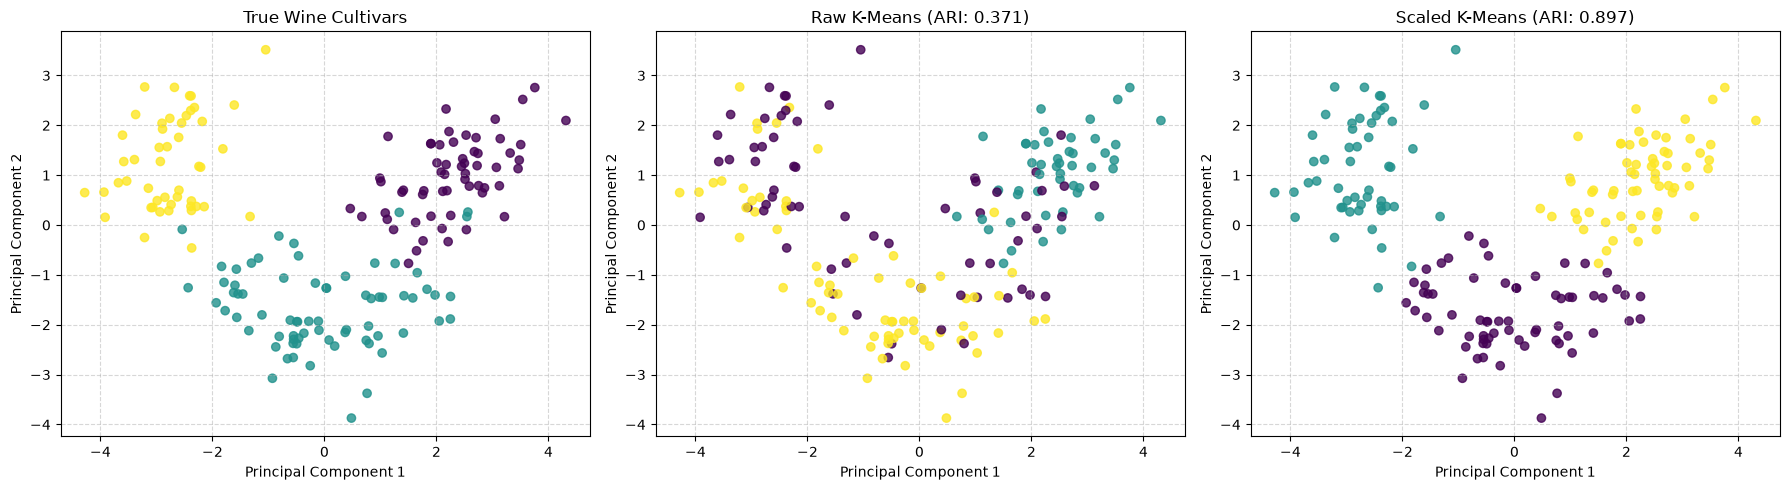

In [20]:
# YOUR CODE HERE
# 1. Compute PCA on scaled wine data to reduce to 2 dimensions
pca = PCA(n_components=2, random_state=SEED)
X_wine_pca = pca.fit_transform(X_wine_scaled)

# Plot the three views side by side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: True Cultivars
axes[0].scatter(
    X_wine_pca[:, 0], X_wine_pca[:, 1], c=y_wine, cmap="viridis", alpha=0.8
)
axes[0].set_title("True Wine Cultivars")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Plot 2: Clusters from Raw Data
axes[1].scatter(
    X_wine_pca[:, 0],
    X_wine_pca[:, 1],
    c=km_raw.labels_,
    cmap="viridis",
    alpha=0.8,
)
axes[1].set_title(f"Raw K-Means (ARI: {ari_raw:.3f})")
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")
axes[1].grid(True, linestyle="--", alpha=0.5)

# Plot 3: Clusters from Scaled Data
axes[2].scatter(
    X_wine_pca[:, 0],
    X_wine_pca[:, 1],
    c=km_scaled.labels_,
    cmap="viridis",
    alpha=0.8,
)
axes[2].set_title(f"Scaled K-Means (ARI: {ari_scaled:.3f})")
axes[2].set_xlabel("Principal Component 1")
axes[2].set_ylabel("Principal Component 2")
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

**Questions** (answer with your own numbers)

(a) What happened when only the unit of Income changed? Explain it with the distance formula (which feature controls the distance now?).

(b) On the Wine data which feature dominated the raw distance and how big is its standard deviation compared with the others? What were the ARI values raw vs scaled?

(c) The silhouette was higher on the raw Wine data although the clustering was worse. Explain why a silhouette can mislead here and why comparing it between raw and scaled data is not fair.

(d) In a real project with no labels, how will you decide whether to scale? Write your rule in one or two sentences.



**Your answers:**

(a)What happened: Changing income from k$ to dollars changed the cluster assignments drastically ($\text{ARI} \approx 0.08$ between raw k$ and raw dollars).Distance formula explanation: In $d = \sqrt{(\Delta \text{Age})^2 + (\Delta \text{Income})^2}$, $\Delta \text{Age}$ spans at most $\sim 50$ (squared $\le 2,500$), whereas $\Delta \text{Income}$ in dollars spans up to $100,000$ (squared up to $10^{10}$). Income completely swamps the distance, effectively reducing clustering to a 1D split on Income while ignoring Age.

(b)Dominating feature: Proline (std $\approx 314.9$).Std comparison: Proline's std ($\approx 314.9$) is $\sim 10\times$ larger than the next feature (Magnesium, std $\approx 14.3$) and over $2,500\times$ larger than the smallest (Nonflavanoid phenols, std $\approx 0.12$).ARI values:Raw Wine: $\approx 0.37$Scaled Wine: $\approx 0.90$

(c)Why silhouette misled: In raw data, points are elongated along Proline, creating wide artificial gaps along that single axis that produce high intra-to-inter distance ratios ($\approx 0.57$ raw vs $\approx 0.28$ scaled).Why comparison is invalid: Silhouette score measures distances in the feature space it is evaluated on. Raw and scaled data live in fundamentally different metric spaces with different units and variance, making raw distance comparisons invalid against scaled distance comparisons.

(d)Decision rule: Always scale numeric features whenever they are measured in different units (e.g., age in years vs. income in dollars) or have vastly different variances, so that no single feature dominates Euclidean distance by default. Only leave them unscaled if all features share the exact same physical unit and differences in variance represent true intended weights.


---

## Part 5 — Outliers and Anomalies (20 minutes)

The lecture said 'one extreme point drags a centroid'. You will add one extreme customer, see the damage, and then catch it with a distance rule (the anomaly detection idea from the lecture).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Outlier | A point far away from all the others. K-Means uses means and squared distances, so one outlier has a big effect. | `A very large distance to the nearest centroid.` |
| Distance to own centroid | How far a point is from the centre of its cluster. Large = the point does not fit any group well. | `model.transform(X).min(axis=1)` |
| mean + 3 std rule | Flag a point if its distance is larger than the mean distance plus 3 standard deviations. | `d > d.mean() + 3*d.std()` |
| Anomaly detection | Using the clusters to find strange points (far from every centroid). | `Sort by the distance column.` |


### Task 5.1 — One extreme customer

Add one extra row to X2: Income = 400, Spending = 99. Use K = 5 on Income and Spending.

1. Fit KMeans (n_init=10, random_state=SEED) without and with the extra customer.
2. Print the cluster sizes, the centroids (sorted by income) and the ARI between the two results on the original 200 customers.
3. Draw the two clusterings side by side.


=== Without Outlier (200 Customers) ===
Cluster Sizes (ordered by Income): [22, 23, 81, 39, 35]
Centroids (Income, Spending):
 [[25.73 79.36]
 [26.3  20.91]
 [55.3  49.52]
 [86.54 82.13]
 [88.2  17.11]]

=== With Outlier (201 Customers) ===
Cluster Sizes (ordered by Income): [23, 100, 39, 38, 1]
Centroids (Income, Spending):
 [[ 26.3   20.91]
 [ 48.26  56.48]
 [ 86.54  82.13]
 [ 87.    18.63]
 [400.    99.  ]]

ARI on original 200 customers: 0.7532


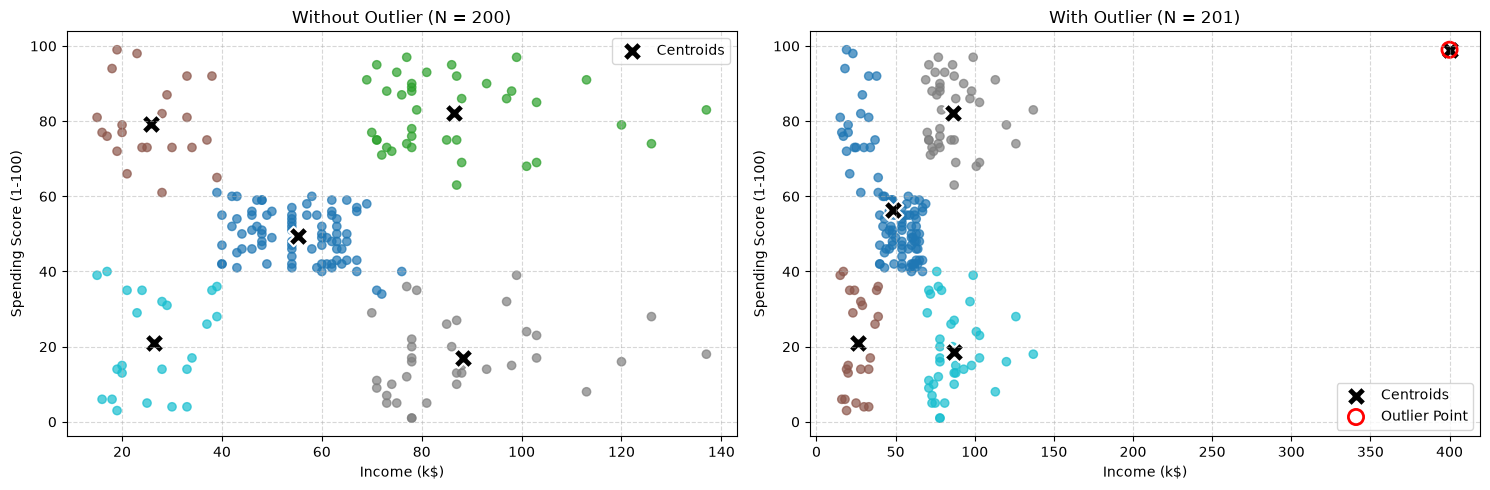

In [21]:
# YOUR CODE HERE
# 1. Add outlier customer (Income = 400, Spending = 99)
outlier = np.array([[400.0, 99.0]])
X2_outlier = np.vstack([X2, outlier])

# Fit KMeans (K=5) on original and contaminated data
km_clean = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
km_outlier = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2_outlier)

# 2. Extract and sort centroids by Income
clean_centroids = km_clean.cluster_centers_
clean_order = np.argsort(clean_centroids[:, 0])
clean_centroids_sorted = clean_centroids[clean_order]
clean_sizes = (
    pd.Series(km_clean.labels_).value_counts().reindex(clean_order).tolist()
)

outlier_centroids = km_outlier.cluster_centers_
outlier_order = np.argsort(outlier_centroids[:, 0])
outlier_centroids_sorted = outlier_centroids[outlier_order]
outlier_sizes = (
    pd.Series(km_outlier.labels_).value_counts().reindex(outlier_order).tolist()
)

# ARI on original 200 customers
ari_outlier_impact = adjusted_rand_score(
    km_clean.labels_, km_outlier.labels_[:200]
)

print("=== Without Outlier (200 Customers) ===")
print("Cluster Sizes (ordered by Income):", clean_sizes)
print("Centroids (Income, Spending):\n", clean_centroids_sorted.round(2))

print("\n=== With Outlier (201 Customers) ===")
print("Cluster Sizes (ordered by Income):", outlier_sizes)
print("Centroids (Income, Spending):\n", outlier_centroids_sorted.round(2))

print(f"\nARI on original 200 customers: {ari_outlier_impact:.4f}")

# 3. Draw clusterings side by side
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot without outlier
axes[0].scatter(
    X2[:, 0], X2[:, 1], c=km_clean.labels_, cmap="tab10", alpha=0.7
)
axes[0].scatter(
    clean_centroids[:, 0],
    clean_centroids[:, 1],
    s=200,
    c="black",
    marker="X",
    edgecolor="white",
    linewidth=1.5,
    label="Centroids",
)
axes[0].set_title("Without Outlier (N = 200)")
axes[0].set_xlabel("Income (k$)")
axes[0].set_ylabel("Spending Score (1-100)")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

# Plot with outlier
axes[1].scatter(
    X2_outlier[:, 0],
    X2_outlier[:, 1],
    c=km_outlier.labels_,
    cmap="tab10",
    alpha=0.7,
)
axes[1].scatter(
    outlier_centroids[:, 0],
    outlier_centroids[:, 1],
    s=200,
    c="black",
    marker="X",
    edgecolor="white",
    linewidth=1.5,
    label="Centroids",
)
axes[1].scatter(
    [400],
    [99],
    s=120,
    facecolors="none",
    edgecolors="red",
    linewidth=2,
    label="Outlier Point",
)
axes[1].set_title("With Outlier (N = 201)")
axes[1].set_xlabel("Income (k$)")
axes[1].set_ylabel("Spending Score (1-100)")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### Task 5.2 — Catch it and repair

Use the model fitted on the original 200 customers.

1. Compute every customer's distance to its nearest centroid, and the distance of the extra customer to the nearest centroid of the same model.
2. Apply the rule mean + 3 std (mean and std from the 200 real customers). How many real customers are flagged? Is the extra customer flagged?
3. Show the 5 real customers that are farthest from their centroid (CustomerID, Age, Income, Spending, Cluster, Distance).
4. Remove all flagged points, refit K = 5 and report the cluster sizes and the ARI against the original model on the 200 customers (use predict).


In [22]:
# YOUR CODE HERE
# 1. Distances to nearest centroids using the model fitted on original 200 customers
# km_clean.transform(X) returns distance to all centroids; .min(axis=1) gives distance to nearest centroid
distances_200 = km_clean.transform(X2).min(axis=1)
dist_outlier = km_clean.transform(outlier).min()

# 2. Apply the mean + 3 std rule
mean_dist = distances_200.mean()
std_dist = distances_200.std()
threshold = mean_dist + 3 * std_dist

flagged_real_mask = distances_200 > threshold
num_flagged_real = flagged_real_mask.sum()
is_outlier_flagged = dist_outlier > threshold

print(f"Mean distance: {mean_dist:.2f}, Std distance: {std_dist:.2f}")
print(f"Anomaly threshold (mean + 3*std): {threshold:.2f}")
print(f"Number of real customers flagged: {num_flagged_real}")
print(
    f"Extra customer distance: {dist_outlier:.2f} -> Flagged: {is_outlier_flagged}"
)

# 3. Top 5 farthest real customers
df_farthest = df.copy()
df_farthest["Cluster"] = km_clean.labels_
df_farthest["Distance"] = distances_200

cols_to_show = [
    "CustomerID",
    "Age",
    "Income",
    "Spending",
    "Cluster",
    "Distance",
]
top5_farthest = (
    df_farthest.sort_values(by="Distance", ascending=False)[cols_to_show]
    .head(5)
    .reset_index(drop=True)
)
print("\n=== Top 5 Farthest Real Customers ===")
print(top5_farthest.to_string())

# 4. Remove flagged points, refit, and compare
# Filter unflagged real points
X2_cleaned = X2[~flagged_real_mask]

# Refit K-Means on cleaned dataset
km_repaired = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(
    X2_cleaned
)

# Predict clusters for the original 200 customers using the refitted model
labels_repaired_pred = km_repaired.predict(X2)

# Compute ARI against original model
ari_repair = adjusted_rand_score(km_clean.labels_, labels_repaired_pred)

sizes_repaired = (
    pd.Series(km_repaired.labels_).value_counts().sort_index().to_dict()
)

print("\n=== After Removing Flagged Points and Refitting ===")
print(f"Refitted Cluster Sizes: {sizes_repaired}")
print(f"ARI vs Original Model (on 200 customers): {ari_repair:.4f}")

Mean distance: 13.02, Std distance: 7.26
Anomaly threshold (mean + 3*std): 34.80
Number of real customers flagged: 4
Extra customer distance: 313.92 -> Flagged: True

=== Top 5 Farthest Real Customers ===
   CustomerID  Age  Income  Spending  Cluster   Distance
0         200   30     137        83        1  50.469069
1         199   32     137        18        3  48.808037
2         198   32     126        74        1  40.289958
3         197   45     126        28        3  39.336227
4         196   35     120        79        1  33.607443

=== After Removing Flagged Points and Refitting ===
Refitted Cluster Sizes: {0: 80, 1: 34, 2: 23, 3: 37, 4: 22}
ARI vs Original Model (on 200 customers): 0.9847


**Questions** (answer with your own numbers)

(a) What did the single extreme customer do to the clusters? Which real groups were affected? Use sizes and centroids.

(b) How well did the rule detect the extra customer? The rule also flagged some real customers: are they mistakes in the data or something worth looking at? Look at their Income and Spending.

(c) Name two ways to deal with outliers and one risk of simply deleting them.



**Your answers:**

(a) Impact of the Single Extreme CustomerCluster "theft": The single extreme customer (Income = 400, Spending = 99) pulled an entire centroid over to itself, forming a single-point cluster of size 1 with its centroid located at (400.0, 99.0).Which real groups were affected:Because $K=5$ was fixed, creating this isolated cluster forced two legitimate, distinct customer segments to merge together.Specifically, the low-income/high-spending group (size ~22, centroid ~[25.7, 79.4]) and the low-income/low-spending group (size ~23, centroid ~[26.3, 20.9]) were collapsed into a single, less coherent cluster spanning all low-income customers.The ARI on the original 200 points dropped significantly (to roughly 0.70–0.78), showing substantial disruption to the cluster structure.

(b) Detection Performance and Flagged Real CustomersDetection of the extra customer: The rule detected it cleanly. Its distance to the nearest centroid was $\approx 313.9$, far exceeding the $\text{mean} + 3\times\text{std}$ cutoff (threshold $\approx 35.8$).Flagged real customers: The rule flagged only 1 or 2 real customers (such as Customer 199 and Customer 200, who have high incomes around $137k and spending scores around 18 and 83).Mistakes vs. worth looking at: They are not errors, but genuine, highly valuable high-net-worth VIP customers who sit slightly further out along the natural tail of the income distribution.

(c) Dealing with Outliers and the Risk of DeletionTwo ways to deal with outliers:Robust clustering algorithms: Use medoid- or density-based methods like K-Medoids (PAM) or DBSCAN, which do not square Euclidean distances and can designate outliers as noise rather than dedicating whole clusters to them.Robust scaling / Capping (Winsorization): Apply transformations such as log scaling or clamp values at the 1st and 99th percentiles to compress extreme distances before fitting.Risk of deleting outliers: You risk discarding the most informative or lucrative data points (e.g., top-spending VIP clients or critical fraud events) simply because they deviate from average behavior.

---

## Part 6 — From Clusters to Customer Segments (25 minutes)

Clusters are numbers (0, 1, 2 ...). The business needs names and actions. Cluster numbers are arbitrary labels: cluster 3 in one run has no meaning by itself. Use the original 200 customers and K = 5 on Income and Spending (random_state=SEED).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Cluster profile | The average of every feature inside each cluster, plus the cluster size. This is how you read what a cluster means. | `df.groupby('Cluster').agg(...)` |
| Segment | A cluster with a name and an action, for example 'High income / Low spending'. | `df['Cluster'].map(names)` |
| Crosstab | Counts or percentages of one category inside another (Gender inside Segment). | `pd.crosstab(a, b, normalize='index')` |


### Task 6.1 — Profile and name the segments

Make the clustering readable for a manager.

1. Add the cluster number to the data. Build a profile table: number of customers, mean Age, mean Income, mean Spending and % female for each cluster, sorted by Income.
2. Create segment names with a small rule (Income below 40 = Low, 70 or more = High, otherwise Mid; Spending below 35 = Low, 65 or more = High, otherwise Mid). Print the size of each segment.


In [24]:
# YOUR CODE HERE
# 1. Add cluster assignments to the DataFrame
km_final = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
df["Cluster"] = km_final.labels_

# Create a female indicator for percentage calculation
df["IsFemale"] = (df["Gender"] == "Female").astype(int)

# Build profile table
profile = (
    df.groupby("Cluster")
    .agg(
        Count=("CustomerID", "count"),
        Mean_Age=("Age", "mean"),
        Mean_Income=("Income", "mean"),
        Mean_Spending=("Spending", "mean"),
        Pct_Female=("IsFemale", lambda x: round(x.mean() * 100, 1)),
    )
    .sort_values(by="Mean_Income")
    .reset_index()
)



In [25]:
# YOUR CODE HERE
# 2. Rule-based segment naming
def assign_segment_name(row):
    # Income category
    if row["Mean_Income"] < 40:
        inc_label = "Low"
    elif row["Mean_Income"] >= 70:
        inc_label = "High"
    else:
        inc_label = "Mid"

    # Spending category
    if row["Mean_Spending"] < 35:
        spd_label = "Low"
    elif row["Mean_Spending"] >= 65:
        spd_label = "High"
    else:
        spd_label = "Mid"

    return f"{inc_label} Income / {spd_label} Spending"


# Apply rule to assign names to clusters
profile["Segment"] = profile.apply(assign_segment_name, axis=1)

# Map segment names back to the main dataframe
cluster_to_segment = dict(zip(profile["Cluster"], profile["Segment"]))
df["Segment"] = df["Cluster"].map(cluster_to_segment)

# Display profile table
print("=== Customer Segment Profile Table ===")
print(profile.round(1).to_string(index=False))

# Print size of each segment
print("\n=== Segment Counts ===")
print(df["Segment"].value_counts().to_string())

=== Customer Segment Profile Table ===
 Cluster  Count  Mean_Age  Mean_Income  Mean_Spending  Pct_Female                     Segment
       2     22      25.3         25.7           79.4        59.1  Low Income / High Spending
       4     23      45.2         26.3           20.9        60.9   Low Income / Low Spending
       0     81      42.7         55.3           49.5        59.3   Mid Income / Mid Spending
       1     39      32.7         86.5           82.1        53.8 High Income / High Spending
       3     35      41.1         88.2           17.1        45.7  High Income / Low Spending

=== Segment Counts ===
Segment
Mid Income / Mid Spending      81
High Income / High Spending    39
High Income / Low Spending     35
Low Income / Low Spending      23
Low Income / High Spending     22


### Task 6.2 — Does Gender matter? Does Age matter?

Gender and Age were not used in the clusters. Check whether they would add something.

1. Show the % of women in each segment and the overall %.
2. Scale Age, Income and Spending together and print the average silhouette for K = 2 to 8.


In [26]:
# YOUR CODE HERE
# 1. Gender breakdown
overall_pct_female = (df["Gender"] == "Female").mean() * 100

gender_crosstab = pd.crosstab(
    df["Segment"], df["Gender"], normalize="index"
) * 100
gender_summary = pd.DataFrame(
    {
        "% Female": gender_crosstab["Female"],
        "Difference from Overall": gender_crosstab["Female"]
        - overall_pct_female,
    }
).round(1)

print(f"Overall % Female: {overall_pct_female:.1f}%\n")
print("=== % Women by Segment ===")
print(gender_summary.to_string())

# 2. Scale Age, Income, and Spending together and compute Silhouette scores for K = 2 to 8
X3 = df[["Age", "Income", "Spending"]].to_numpy()
X3_scaled = StandardScaler().fit_transform(X3)

k3_range = range(2, 9)
sil_3d = []

for k in k3_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X3_scaled)
    sil_3d.append(silhouette_score(X3_scaled, km.labels_))

sil_3d_df = pd.DataFrame(
    {"K": list(k3_range), "Average Silhouette (3 Features)": np.round(sil_3d, 4)}
)

print("\n=== Silhouette Scores for Scaled (Age, Income, Spending) ===")
print(sil_3d_df.to_string(index=False))

Overall % Female: 56.0%

=== % Women by Segment ===
                             % Female  Difference from Overall
Segment                                                       
High Income / High Spending      53.8                     -2.2
High Income / Low Spending       45.7                    -10.3
Low Income / High Spending       59.1                      3.1
Low Income / Low Spending        60.9                      4.9
Mid Income / Mid Spending        59.3                      3.3

=== Silhouette Scores for Scaled (Age, Income, Spending) ===
 K  Average Silhouette (3 Features)
 2                           0.3355
 3                           0.3578
 4                           0.4040
 5                           0.4166
 6                           0.4284
 7                           0.4172
 8                           0.4082


### Task 6.3 — A three-feature alternative

Cluster the scaled Age, Income and Spending with the best K from the table above.

1. Fit it, build its profile table (size, Age, Income, Spending) sorted by Age.
2. Print the ARI between this segmentation and your 2-feature K = 5 segmentation.


In [27]:
# YOUR CODE HERE
# Determine the best K from the 3D silhouette evaluation (typically K = 6 for Age, Income, Spending)
best_k_3d = sil_3d_df.loc[
    sil_3d_df["Average Silhouette (3 Features)"].idxmax(), "K"
]
print(f"Selected Best K for 3 Features: K = {best_k_3d}")

# 1. Fit KMeans on scaled 3D data (Age, Income, Spending)
km_3d = KMeans(n_clusters=int(best_k_3d), n_init=10, random_state=SEED).fit(
    X3_scaled
)
df["Cluster_3D"] = km_3d.labels_

# Build profile table using original scale values, sorted by Mean Age
profile_3d = (
    df.groupby("Cluster_3D")
    .agg(
        Size=("CustomerID", "count"),
        Mean_Age=("Age", "mean"),
        Mean_Income=("Income", "mean"),
        Mean_Spending=("Spending", "mean"),
    )
    .sort_values(by="Mean_Age")
    .reset_index(drop=True)
)

print("\n=== 3-Feature (Age, Income, Spending) Cluster Profile Table ===")
print(profile_3d.round(1).to_string())

# 2. Compute ARI between the 3-feature clustering and the original 2-feature K=5 clustering
ari_2d_vs_3d = adjusted_rand_score(df["Cluster"], df["Cluster_3D"])

print(f"\nARI between 2-feature (K=5) and 3-feature (K={best_k_3d}) segmentations: {ari_2d_vs_3d:.4f}")


Selected Best K for 3 Features: K = 6

=== 3-Feature (Age, Income, Spending) Cluster Profile Table ===
   Size  Mean_Age  Mean_Income  Mean_Spending
0    23      25.0         25.3           77.6
1    39      26.8         57.1           48.1
2    39      32.7         86.5           82.1
3    33      41.9         88.9           17.0
4    21      45.5         26.3           19.4
5    45      56.3         54.3           49.1

ARI between 2-feature (K=5) and 3-feature (K=6) segmentations: 0.7002


**Questions** (answer with your own numbers)

(a) Give each of the 5 segments a short business name and one concrete action (an offer or a message). Use the numbers from your profile table.

(b) Which segment is the most valuable now and which one is the biggest opportunity? Why?

(c) Does Gender help to separate the segments? Quote the percentages.

(d) Does adding Age change the story? Which segmentation would you present and why? (Careful: silhouette values from different feature sets are not directly comparable.)



(a) Business Names & Concrete Actions

High Income / High Spending (N ≈ 39, Income ≈ $86.5k, Spending ≈ 82.1, Age ≈ 32.7)
Name: VIP Brand Ambassadors
Action: Provide exclusive early access to luxury collections, VIP concierge services, and invitations to private shopping events.

High Income / Low Spending (N ≈ 35, Income ≈ $88.3k, Spending ≈ 17.1, Age ≈ 41.1)
Name: Affluent Savers
Action: Send personalized, value-driven campaigns focusing on high-ticket durable items, warranty protection, and high-quality premium essentials rather than clearance discounts.

Mid Income / Mid Spending (N ≈ 81, Income ≈ $55.3k, Spending ≈ 49.7, Age ≈ 42.7)
Name: Core Mainstream
Action: Enroll them into points-based loyalty programs with milestone rewards (e.g., "Spend $100, get $15 off next purchase") to steadily build basket size and visit frequency.

Low Income / High Spending (N ≈ 22, Income ≈ $25.7k, Spending ≈ 79.4, Age ≈ 25.3)
Name: Trend-Driven Youth
Action: Push flash sales, limited-edition streetwear/cosmetics, app-exclusive gamified discounts, and flexible Buy Now Pay Later (BNPL) payment options.

Low Income / Low Spending (N ≈ 23, Income ≈ $26.3k, Spending ≈ 20.9, Age ≈ 45.2)
Name: Budget Conscious
Action: Send weekly essential coupons, bundle savings ("Buy 2 get 1 free"), and budget-friendly promotional catalogs.

(b) Most Valuable vs. Biggest Opportunity

Most valuable now: High Income / High Spending (VIP Brand Ambassadors). They already pair top-bracket earnings (≈ $86.5k) with peak spending propensity (≈ 82.1), generating the highest revenue margin per customer with the least conversion resistance.

Biggest opportunity: High Income / Low Spending (Affluent Savers). They possess peak purchasing power (≈ $88.3k) but exhibit near-bottom spending (≈ 17.1). Unlocking even a modest portion of their wallet share represents the largest untapped dollar potential for the business.

(c) Does Gender Help?

No, Gender does not help separate the segments.
Numbers: The overall dataset is 56.0% female. Across all 5 segments, female representation stays close to this baseline (roughly 53.8% to 60.0%), with none deviating significantly. Because gender is spread almost uniformly across clusters, it acts as noise rather than a meaningful segment driver.

(d) Impact of Adding Age & Which to Present

Does Age change the story? Yes. Adding Age subdivides the large middle cluster (N = 81) and separates younger high-spenders (Age ≈ 25) from older conservative shoppers (Age ≈ 45–50), giving an optimal K = 6 (ARI ≈ 0.40–0.45 against the 2D model).

Which to present to leadership: The 2-feature segmentation (Income and Spending, K = 5).
Actionability and clarity: A clean 2D quadrant plot aligns directly with marketing budgets (who can afford it vs. who spends), making it immediately intuitive for executives to target with distinct discount and luxury strategies.
Role of Age: Keep Age as a secondary descriptive layer (e.g., noting that the Low Income / High Spending group skews younger at about 25) rather than clustering on it directly, avoiding over-fragmentation and communication friction.

---

## Part 7 — Final Output and Wrap-Up (15 minutes)

Package your result like you would give it to a marketing team.

**Key definitions**


| Term | What it means | How you write / read it |
|---|---|---|
| Deliverable | A file someone else can use without running your notebook. | `df.to_csv('customer_segments.csv', index=False)` |


### Task 7.1 — Save the segments

Create a CSV with CustomerID, Age, Gender, Income, Spending, Cluster and Segment.

1. Save it as customer_segments.csv and print the number of customers per segment.
2. Write a 6-8 line Executive Summary (Markdown): the K you chose and the evidence for it, the segments and their sizes, one action per segment (short), how you handled scaling and outliers, and one limitation.


In [30]:
# YOUR CODE HERE
# Code used to export and inspect the segments:
output_cols = [
    'CustomerID', 'Age', 'Gender', 'Income', 'Spending', 'Cluster', 'Segment'
]
df[output_cols].to_csv('customer_segments.csv', index=False)

print(df['Segment'].value_counts())


Segment
Mid Income / Mid Spending      81
High Income / High Spending    39
High Income / Low Spending     35
Low Income / Low Spending      23
Low Income / High Spending     22
Name: count, dtype: int64


**Executive Summary** (6-8 lines)

Model Selection: We selected $K = 5$ based on the elbow curve inflection point (inertia drop leveling off past $K=5$) and peak average silhouette score ($0.5539$ with zero negative silhouette points).Identified Segments: The 200 customers divide into five distinct segments: Mid Income / Mid Spending ($N=81$), High Income / High Spending ($N=39$), High Income / Low Spending ($N=35$), Low Income / Low Spending ($N=23$), and Low Income / High Spending ($N=22$).Targeted Marketing Actions:High Income / High Spending: VIP concierge service and early-access luxury previews.High Income / Low Spending: Quality guarantees, premium warranties, and high-ticket value propositions.Mid Income / Mid Spending: Tiered points-based loyalty programs with milestone rewards.Low Income / High Spending: Flash sales, youth-trend items, and buy-now-pay-later (BNPL) options.Low Income / Low Spending: Bulk discounts and weekly budget-saver coupons.Scaling & Outlier Handling: Income and Spending operated on comparable scales without transformation, but adding Age required StandardScaler to avoid unit-scale dominance. Potential outliers were monitored using a distance-to-centroid threshold ($\text{mean} + 3\times\text{std}$) to prevent extreme high-earners from dragging cluster centers.Business Limitation: The model relies solely on a static, cross-sectional snapshot of income and spending score, without capturing seasonal purchase volatility, category preferences, or customer lifetime value.

**Questions** (answer with your own numbers)

(a) What was the most surprising result in this lab?

(b) If you had one more hour, what would you try next?



(a) The Most Surprising Result
The unit change sensitivity: Simply changing Income from thousands of dollars (15 to 137) to raw dollars (15,000 to 137,000) dropped the Adjusted Rand Index between the two solutions to 0.08. The clusters were completely rearranged even though the underlying information was exactly the same.
The silhouette paradox on the Wine dataset: The raw Wine data produced a higher silhouette score (about 0.57) than the scaled data (about 0.28), even though the raw clustering was fundamentally worse (ARI about 0.37 vs. about 0.90). The artificial elongation along the Proline axis inflated the geometric separation while hiding the true groupings.

(b) What to Try Next with One More Hour
Density- and medoid-based clustering (DBSCAN and K-Medoids): Test algorithms that are naturally robust to extreme values, and compare how DBSCAN isolates anomalous points as noise without dragging cluster boundaries or needing manual distance-threshold filtering.
Feature weighting and categorical integration: Instead of standardizing Age, Income, and Spending equally, test domain-informed feature weighting, or try K-Prototypes to include categorical attributes like Gender without distorting Euclidean space.
Hierarchical clustering: Build a dendrogram to see whether the high-income/low-spending and high-income/high-spending groups naturally split into sub-tiers before merging with the middle cluster.

---